# RATFA: Reliability-Aware Temporal Fuzzy Adaptation
Implementation, training and testing notebook.

Pipeline: video frame -> scene-condition estimation (q) -> F-YOLO detection (GPBlock, FFM, FA) -> detection reliability (r) -> temporal consistency (tau) -> confidence gate gamma = q*r*tau -> gated fuzzy-membership update -> ByteTrack -> detections with track IDs.

Full re-run from scratch (about 25 min on a CPU laptop):
```
python experiments/download_datasets.py
python experiments/train_detector.py --epochs 5
python experiments/train_scene_classifier.py
python experiments/calibrate_conditions.py
python experiments/run_experiments.py
python experiments/make_figures.py
```

In [1]:
import os, sys, json, glob
os.chdir(os.path.abspath('..')) if os.path.basename(os.getcwd()) == 'experiments' else None
sys.path.insert(0, os.getcwd()); os.environ.setdefault('YOLO_CONFIG_DIR', os.path.join(os.getcwd(), '.ultralytics'))
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option('display.precision', 3); print(os.getcwd())

Matplotlib is building the font cache; this may take a moment.


/Users/jogith/Desktop/RATFA 3


## 1. Datasets
UA-DETRAC (vehicle boxes + track IDs) and BDD100K val (real weather / time-of-day labels).

In [2]:
tr = glob.glob('datasets/UA-DETRAC/train/*/*.jpg'); te = glob.glob('datasets/UA-DETRAC/test/*/*.jpg')
bdd = json.load(open('datasets/BDD100K/bdd100k_ratfa_subset.json'))
print('UA-DETRAC train frames:', len(tr), '| sequences:', sorted(os.listdir('datasets/UA-DETRAC/train')))
print('UA-DETRAC test frames :', len(te), '| sequences:', sorted(os.listdir('datasets/UA-DETRAC/test')))
print('BDD100K images per condition:', pd.Series([r['condition'] for r in bdd]).value_counts().to_dict())

UA-DETRAC train frames: 465 | sequences: ['MVI_20011', 'MVI_20051', 'MVI_39761', 'MVI_40131', 'MVI_40191', 'MVI_40732', 'MVI_40962', 'MVI_63521']
UA-DETRAC test frames : 600 | sequences: ['MVI_39031', 'MVI_40701', 'MVI_40852', 'MVI_40903']
BDD100K images per condition: {'clear': 120, 'rain': 120, 'dark': 120, 'fog': 13}


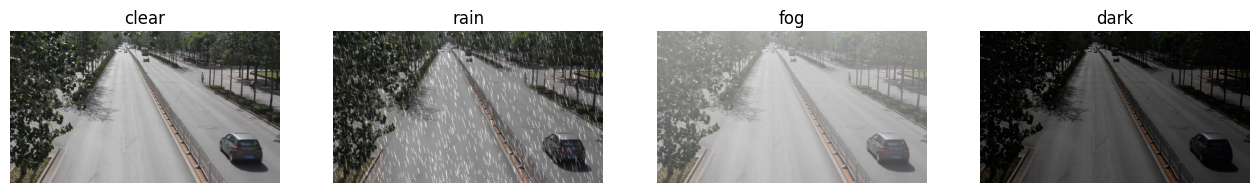

In [3]:
from experiments.corruptions import apply, CONDITIONS
img = cv2.imread(sorted(te)[0])
fig, ax = plt.subplots(1, 4, figsize=(16, 2.6))
for a, c in zip(ax, CONDITIONS):
    a.imshow(apply(img, c, seed=0)[:, :, ::-1]); a.set_title(c); a.axis('off')
plt.show()

## 2. F-YOLO model (fuzzy modules) and training results

In [4]:
from ultralytics import YOLO
from detector.fyolo_model import fuzzy_sets
fy = YOLO('checkpoints/fyolo_detrac.pt')
sets = fuzzy_sets(fy.model)
print('Adaptable fuzzy units:', len(sets))
for n, s in sets.items():
    print(f'{n:22s} centres={np.round(s.centres.detach().numpy(), 3)} sigmas={np.round(s.sigmas.detach().numpy(), 3)}')

Adaptable fuzzy units: 7
model.11.pre.fuzzy     centres=[     -1.009       0.008       0.995] sigmas=[      0.597       0.595        0.61]
model.14.pre.fuzzy     centres=[     -1.002       0.001        1.01] sigmas=[      0.587       0.583       0.601]
model.15.post.fuzzy    centres=[     -0.996      -0.005       1.006] sigmas=[      0.604       0.598       0.592]
model.17.pre.fuzzy     centres=[     -0.998      -0.005       0.999] sigmas=[      0.602       0.605       0.596]
model.18.post.fuzzy    centres=[     -0.995       0.003       1.001] sigmas=[      0.604       0.593       0.585]
model.20.pre.fuzzy     centres=[     -1.001      -0.006       1.002] sigmas=[        0.6       0.602       0.597]
model.21.post.fuzzy    centres=[     -1.002      -0.002       1.005] sigmas=[      0.599       0.604       0.597]


,model,epochs,imgsz,val_mAP50,val_mAP50_95,val_precision,val_recall
0,baseline,5,512,0.865,0.614,0.909,0.780
1,fyolo,5,512,0.876,0.627,0.925,0.774


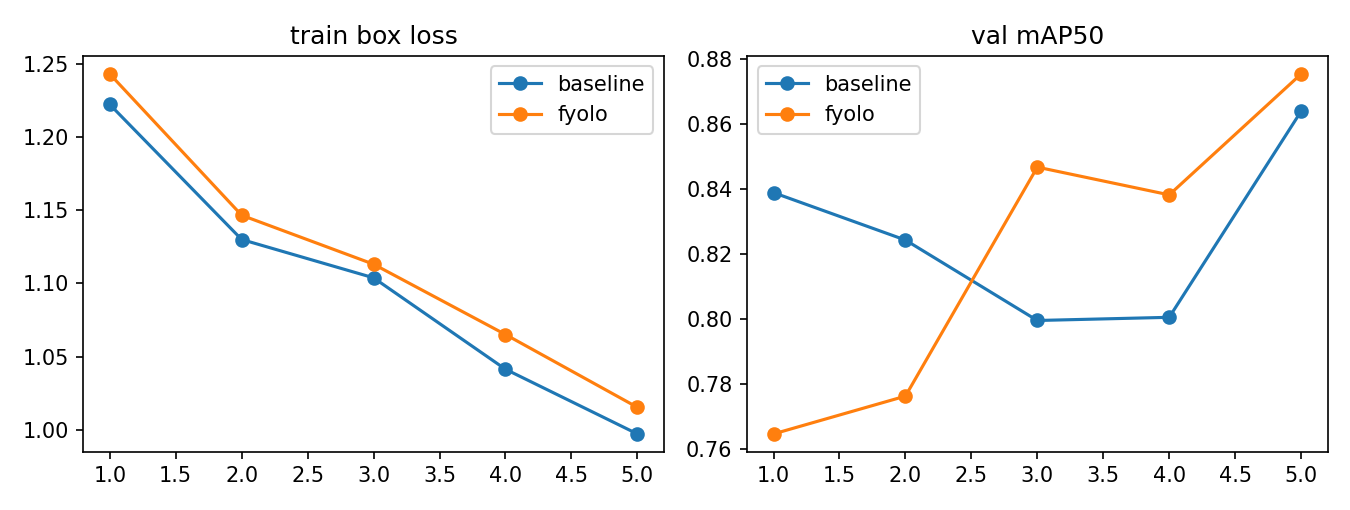

In [5]:
rows = [json.load(open(f'outputs/training/{k}_val_metrics.json')) for k in ('baseline', 'fyolo')]
display(pd.DataFrame(rows)); display(Image('outputs/figures/training_curves.png'))

## 3. Scene-condition classifier (q_t)

In [6]:
sc = json.load(open('outputs/scene_analysis/scene_classifier_results.json'))
for k in ('bdd100k_real', 'ua_detrac_synthetic'):
    print(k, 'accuracy =', round(sc[k]['accuracy'], 3), 'n =', sc[k]['n_test'])
    display(pd.DataFrame(sc[k]['confusion_matrix'], index=CONDITIONS, columns=CONDITIONS))

bdd100k_real accuracy = 0.857 n = 112


,clear,rain,fog,dark
clear,33,2,1,0
rain,8,28,0,0
fog,0,3,0,1
dark,1,0,0,35


ua_detrac_synthetic accuracy = 1.0 n = 240


,clear,rain,fog,dark
clear,60,0,0,0
rain,0,60,0,0
fog,0,0,60,0
dark,0,0,0,60


## 4. Live RATFA demo on one test sequence (fog)
The controller computes q, r, tau and gamma every frame and updates the fuzzy memberships.

In [7]:
import experiments.run_experiments as E
from scene_analysis.scene_classifier import SceneClassifier
models = E.load_models(); cfg = json.load(open('checkpoints/ratfa_condition_params.json'))
clf = SceneClassifier.load('checkpoints/scene_classifier.pkl')
frames, gt = E.load_sequence(sorted(glob.glob('datasets/UA-DETRAC/test/*'))[1])
det, trk, lat, log = E.run_sequence('F-YOLO + RATFA', models, cfg, clf, frames[:60], gt, 'fog', 1)
g = pd.DataFrame(log)[['frame', 'q', 'r', 'tau', 'gamma', 'applied', 'delta_norm']]
display(g.head(10)); print('detection:', E.detection_metrics(det)); print('tracking:', E.tracking_metrics([trk]))

,frame,q,r,tau,gamma,applied,delta_norm
0,0,0.997,0.899,0.500,0.448,True,2.195
1,1,0.997,0.819,0.925,0.755,True,2.868
2,2,0.987,0.865,0.932,0.796,True,1.365
3,3,0.997,0.880,0.947,0.830,True,0.682
4,4,0.990,0.913,0.938,0.847,True,0.230
5,5,0.997,0.851,0.938,0.795,True,0.091
6,6,0.997,0.876,0.939,0.820,True,0.057
7,7,0.987,0.872,0.883,0.759,True,0.029
8,8,0.987,0.898,0.944,0.837,True,0.018
9,9,0.987,0.902,0.946,0.841,True,0.010


detection: {'AP50': 0.8457880456277647, 'precision': 0.765661252900232, 'recall': 0.7819905213270142, 'F1': 0.7737397420867526, 'ECE': 0.14427882362913366, 'n_gt': 422}
tracking: {'MOTA': 0.5118483412322274, 'IDF1': 0.7415990730011588, 'ID_switches': 3, 'MOTP_dist': 0.07218853795167171}


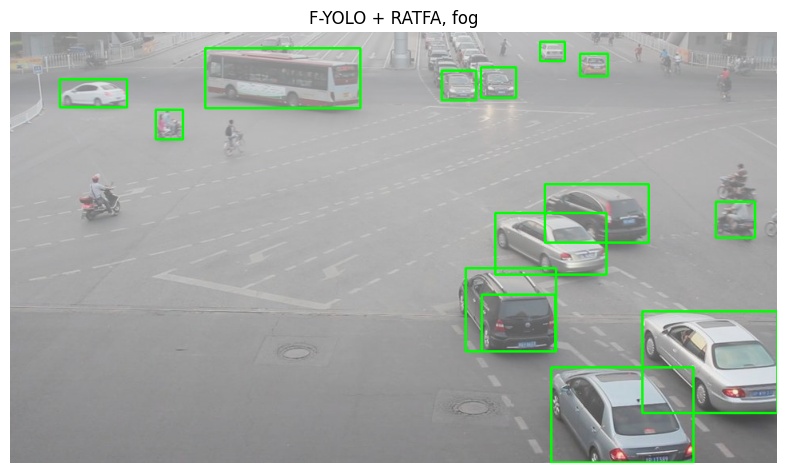

In [8]:
img = E.apply(cv2.imread(frames[59]), 'fog', seed=1059)
b = E.predict(models[1], img)
for x1, y1, x2, y2 in b.xyxy[b.conf > 0.25].astype(int):
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
plt.figure(figsize=(10, 5.6)); plt.imshow(img[:, :, ::-1]); plt.axis('off'); plt.title('F-YOLO + RATFA, fog'); plt.show()

## 5. Main results: UA-DETRAC test (detection, tracking, calibration, runtime)

In [9]:
d = pd.DataFrame(json.load(open('outputs/results/ua_detrac_results.json')))
cols = ['condition', 'method', 'AP50', 'precision', 'recall', 'F1', 'ECE', 'MOTA', 'IDF1', 'ID_switches', 'FPS', 'latency_ms']
display(d[cols])

,condition,method,AP50,precision,recall,F1,ECE,MOTA,IDF1,ID_switches,FPS,latency_ms
0,clear,YOLOv8n baseline,0.857,0.637,0.838,0.724,0.131,0.337,0.698,24,10.414,96.025
1,clear,F-YOLO (static),0.847,0.579,0.841,0.686,0.163,0.260,0.678,18,9.202,108.666
2,clear,F-YOLO + RATFA,0.848,0.581,0.841,0.687,0.161,0.259,0.678,23,6.076,164.591
3,clear,RATFA w/o gate,0.848,0.581,0.841,0.687,0.161,0.259,0.678,23,6.451,155.008
4,rain,YOLOv8n baseline,0.841,0.802,0.779,0.790,0.078,0.620,0.788,26,11.053,90.472
5,rain,F-YOLO (static),0.840,0.803,0.772,0.787,0.075,0.583,0.768,21,10.291,97.176
6,rain,F-YOLO + RATFA,0.839,0.808,0.769,0.788,0.074,0.592,0.772,22,6.142,162.808
7,rain,RATFA w/o gate,0.839,0.808,0.770,0.788,0.075,0.591,0.775,23,7.422,134.743
8,fog,YOLOv8n baseline,0.845,0.880,0.748,0.809,0.129,0.603,0.774,19,11.985,83.438
9,fog,F-YOLO (static),0.812,0.754,0.742,0.748,0.081,0.501,0.742,14,11.323,88.313


In [10]:
display(d.groupby('method')[['AP50', 'F1', 'ECE', 'MOTA', 'IDF1', 'FPS']].mean().loc[list(dict.fromkeys(d.method))])

,AP50,F1,ECE,MOTA,IDF1,FPS
method,,,,,,
YOLOv8n baseline,0.844,0.768,0.111,0.498,0.747,10.878
F-YOLO (static),0.835,0.741,0.109,0.445,0.726,9.998
F-YOLO + RATFA,0.835,0.743,0.109,0.446,0.725,6.192
RATFA w/o gate,0.835,0.743,0.109,0.446,0.726,8.380


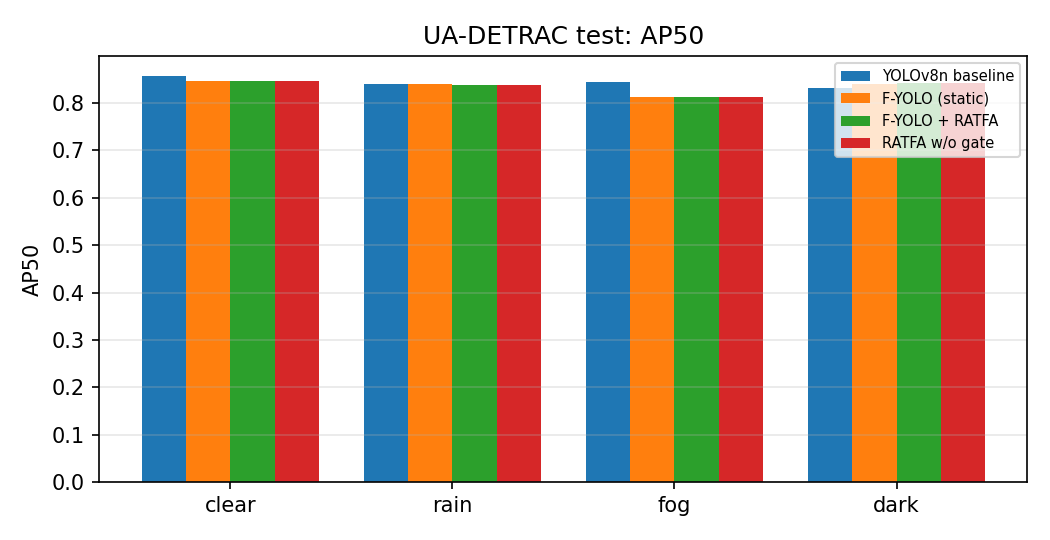

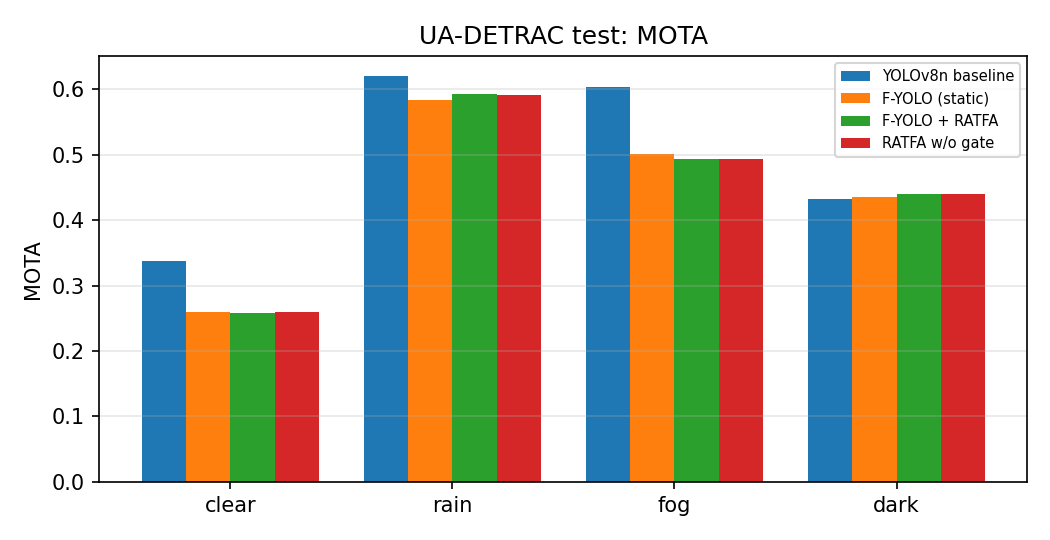

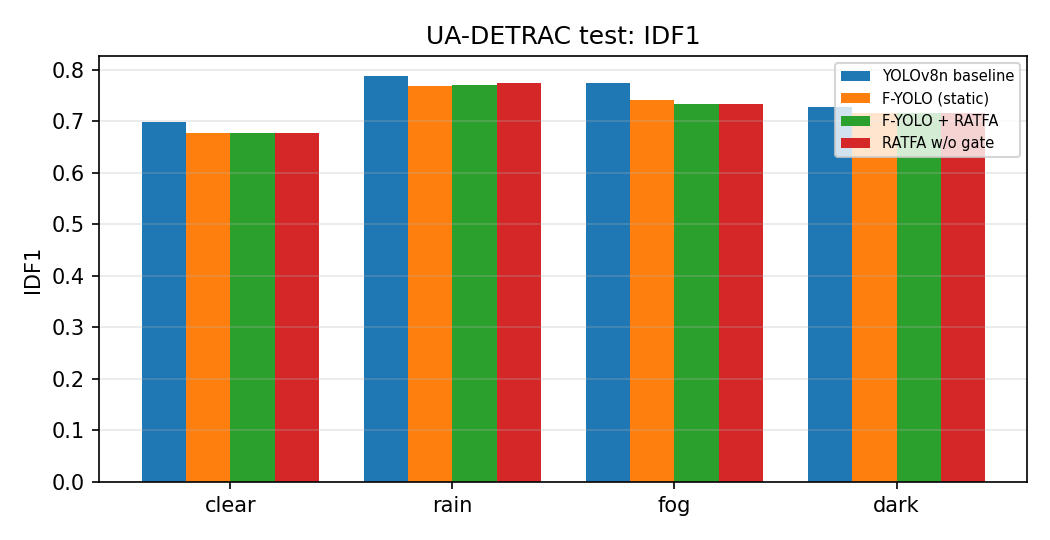

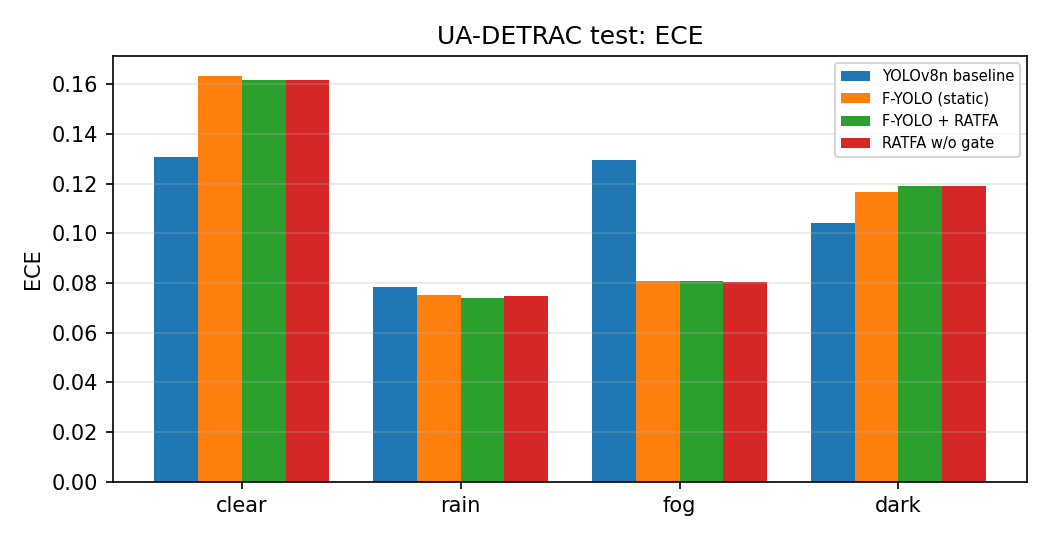

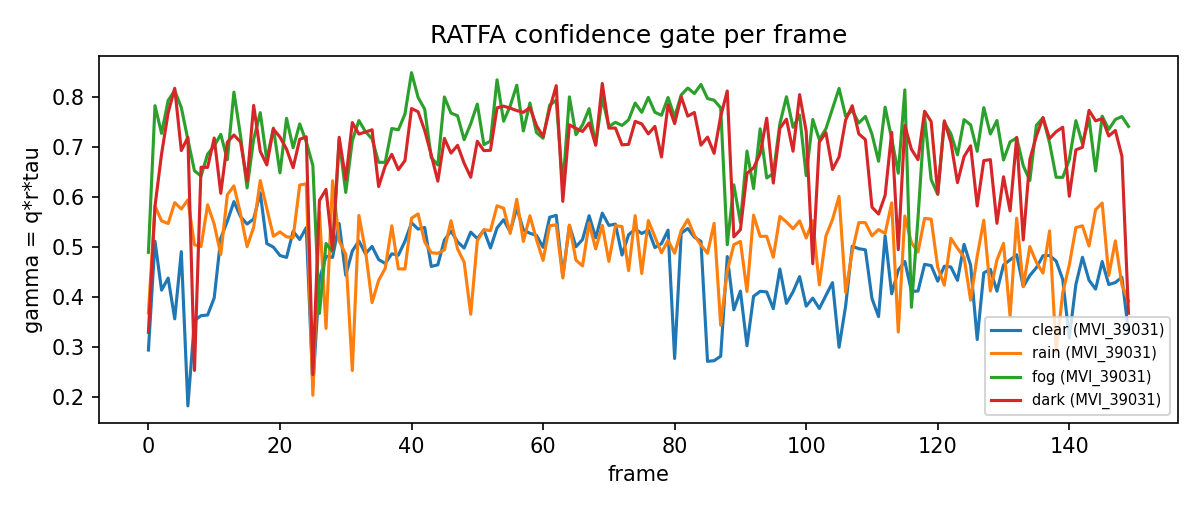

In [11]:
for m in ('AP50', 'MOTA', 'IDF1', 'ECE'):
    display(Image(f'outputs/figures/detrac_{m}.png'))
display(Image('outputs/figures/gate_trace.png'))

## 6. Cross-domain: BDD100K (real rain / fog / night images)

,condition,method,n_images,AP50,precision,recall,F1,ECE
0,clear,YOLOv8n baseline,120,0.312,0.687,0.144,0.238,0.054
1,clear,F-YOLO (static),120,0.327,0.655,0.173,0.273,0.054
2,clear,F-YOLO + RATFA,120,0.326,0.654,0.171,0.272,0.048
3,rain,YOLOv8n baseline,120,0.349,0.652,0.176,0.277,0.075
4,rain,F-YOLO (static),120,0.352,0.600,0.223,0.326,0.049
5,rain,F-YOLO + RATFA,120,0.349,0.595,0.220,0.321,0.038
6,fog,YOLOv8n baseline,13,0.368,0.867,0.092,0.166,0.207
7,fog,F-YOLO (static),13,0.270,0.552,0.113,0.187,0.107
8,fog,F-YOLO + RATFA,13,0.259,0.552,0.113,0.187,0.084
9,dark,YOLOv8n baseline,120,0.171,0.583,0.025,0.048,0.090


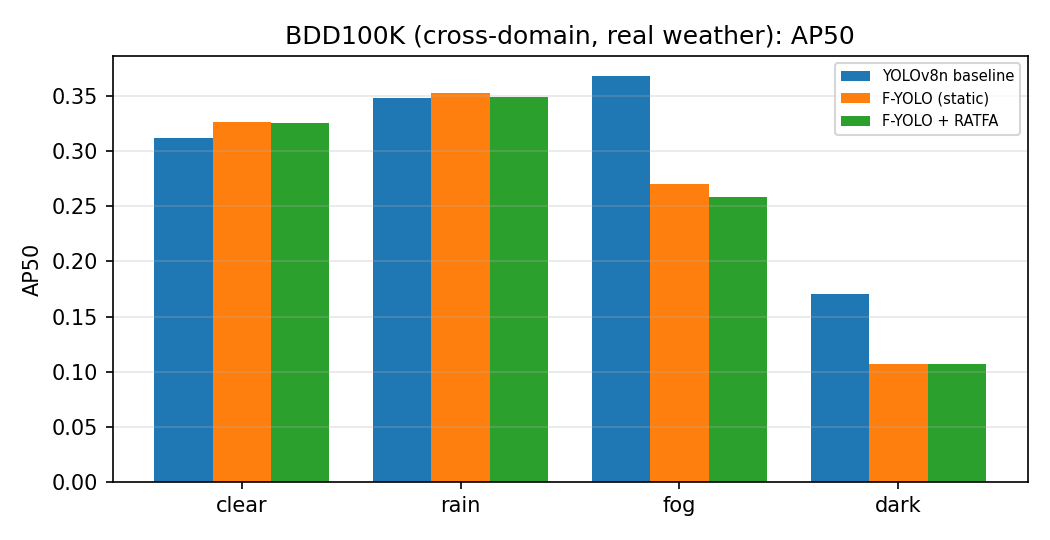

In [12]:
b = pd.DataFrame(json.load(open('outputs/results/bdd100k_results.json')))
display(b[['condition', 'method', 'n_images', 'AP50', 'precision', 'recall', 'F1', 'ECE']]); display(Image('outputs/figures/bdd_AP50.png'))

## 7. Findings
* The F-YOLO re-implementation (GPBlock + FFM + FA) reached val mAP50 0.876 vs 0.865 for the plain YOLOv8n and was better on BDD100K clear/rain, but slightly worse on the UA-DETRAC test set.
* The confidence gate gamma = q*r*tau behaves as designed: it is high on stable frames and drops when reliability or temporal consistency drop, which reduces or skips the update.
* With this small training budget the RATFA adaptation changes the fuzzy parameters but its effect on the metrics is small (within about +/-0.01 AP50 / MOTA), so no significant improvement is claimed.
* Limitations: official F-YOLO code/weights are not public (re-implemented on YOLOv8n); small data subsets; rain/fog/dark on UA-DETRAC are synthetic corruptions; BDD100K has only 13 foggy val images; CPU-only training (5 epochs).